<center>

<img src='https://micro.ce.sharif.edu/lib/tpl/writr/images/logo.svg' alt="SUT logo" width=500 height=300 align=center class="saturate" >


<br>
<font>
<div dir=ltr align=center>
<font color=0F5298 size=7>
    Intelligent Analysis of Biomedical Images <br>
<font color=2565AE size=5>
    Computer Engineering Department <br>
    Dr. Rohban, Fall 2025 <br>
<font color=3C99D size=5>
    Practical Assignment 3 - UNet Segmentation <br>
<font color=696880 size=4>
    By: Alireza Sabounchi

</center>


### Introduction

**U-Net** is a convolutional neural network architecture specifically designed for **biomedical image segmentation**. It was introduced in 2015 by Olaf Ronneberger, Philipp Fischer, and Thomas Brox in the paper **"U-Net: Convolutional Networks for Biomedical Image Segmentation"**.

#### Why was U-Net invented?
Traditional CNNs (like those used for ImageNet classification) lose spatial information due to repeated pooling and striding. This makes it hard to recover precise boundaries, which is a critical requirement in medical imaging where doctors need **pixel-accurate segmentation** of organs, tumors, or lesions.

#### Key Innovation: The "U" Shape
U-Net has a symmetric **encoder-decoder** structure:
- **Encoder (contracting path)**: Captures context and high-level features using downsampling (pooling).
- **Decoder (expansive path)**: Enables precise localization by upsampling and **skip connections** that copy feature maps from the encoder directly to the decoder.

These **skip connections** are the core idea: they preserve fine-grained details (edges, small structures) that would otherwise be lost during downsampling.

U-Net revolutionized medical image analysis and remains the **foundation** of nearly all modern segmentation models (DeepLab, Attention U-Net, TransUNet, nnU-Net, etc.).

#### In This Notebook
You will implement a **modern, practical version** of U-Net using PyTorch (with padding, batch normalization, and a combined loss), which is the same architecture used in top-performing solutions on many segmentation challenges.  
You will train it on brain MRI scans to segment tumors, visualize predictions, and analyze why traditional accuracy is misleading while Dice coefficient is the correct metric for this highly imbalanced task.

### Section 1: Imports and Setup
In this section, import the required libraries for system operations, data handling, visualization, and PyTorch-based deep learning. Run this cell first and note any additional imports you might need for extensions, such as advanced augmentations.

In [1]:
# import system libs
import os
import time
import random
import pathlib
import itertools
from glob import glob
from tqdm import tqdm, tqdm_notebook, tnrange
import time

# import data handling tools
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('darkgrid')
import matplotlib.pyplot as plt
%matplotlib inline
from skimage.color import rgb2gray
from skimage.morphology import label
from skimage.transform import resize
from sklearn.model_selection import train_test_split
from skimage.io import imread, imshow, concatenate_images

# import deep learning libs
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
from torchvision import transforms
from torch.optim import AdamW

# ignore warnings
import warnings
warnings.filterwarnings("ignore")

print('modules loaded')

modules loaded


### Section 2: Dataframe Creation and Splitting
Define functions to create a Pandas dataframe from the dataset directory (pairing images with masks) and split it into train/validation/test sets (80/10/10 ratio) patient-wise to avoid data leakage.

In [ ]:
# ================================================================
# TO DO: Complete the function below to create a DataFrame and perform
# a PATIENT-WISE split (very important: no data leakage between train/val/test!)
#
# Steps you need to implement:
# 1. Find all mask files in the data directory (use glob)
# 2. Create a DataFrame with columns: 'masks_paths' and 'images_paths'
#    → image path is obtained by replacing '_mask' with '' in the mask filename
# 3. Extract the patient_id from the folder name (the parent directory of each file)
# 4. Get the unique list of patient IDs
# 5. Shuffle the patients randomly (use the provided random_state for reproducibility)
# 6. Split the patients into train / validation / test sets using the given ratios
# 7. Create train_df, val_df, test_df by selecting rows that belong to the respective patients
# 8. Print useful statistics (total patients, patients & slices per split)
# 9. Return only the columns ['images_paths', 'masks_paths'] for each split

# ================================================================

def create_df_and_split_patient_wise(data_dir, test_size=0.1, val_size=0.1, random_state=42):
    
    # TO DO: Find all mask files recursively in the data directory
    # Example pattern: f'{data_dir}/*/*_mask*'
    masks_paths = None  
    
    # TO DO: Create DataFrame with mask paths
    df = None
    
    # TO DO: Create column 'images_paths' by removing '_mask' from mask filename
    df['images_paths'] = None  
    
    # TO DO: Extract patient_id from the directory structure (second-to-last folder)
    # Example: path.split('/')[-2]
    df['patient_id'] = None  
    
    # TO DO: Get unique patient IDs and total number of patients
    patients = None
    n_patients = None
    
    # TO DO: Shuffle patients using the random number generator (use the provided random_state)
    rng = None
    
    # TO DO: Compute how many patients go to test and validation sets (integer values)
    test_p = None
    val_p  = None
    
    # TO DO: Slice the shuffled patient list into test / val / train patient IDs
    test_patients  = None
    val_patients   = None
    train_patients = None
    
    # TO DO: Create the three dataframes by filtering on patient_id
    train_df = None
    val_df   = None
    test_df  = None
    
    # Print the statistics exactly as shown in the original output
    print(f"Total patients: {n_patients}")
    print(f"Train: {len(train_patients)} patients, {len(train_df)} slices")
    print(f"Valid: {len(val_patients)} patients, {len(val_df)} slices")
    print(f"Test:  {len(test_patients)} patients, {len(test_df)} slices")
    
    # Return columns for each split
    return (train_df[['images_paths', 'masks_paths']],
            val_df[['images_paths', 'masks_paths']],
            test_df[['images_paths', 'masks_paths']])

# ================================================================
# TO DO: Complete the simpler slice-wise (non-patient-wise) split
#
# This function receives an already-created dataframe (with images_paths & masks_paths)
# and must split it randomly into:
#   • 80% training
#   • 10% validation
#   • 10% test
#
# Use train_test_split from scikit-learn.
# First create a train set (80%) and a temporary remaining set (20%),
# then split the remaining set equally into validation and test.
# ================================================================

def split_df(df):
    
    # TO DO: Split off 80% of the data for training, keep the rest in dummy_df
    train_df, dummy_df = None, None
    
    # TO DO: Split the remaining dummy_df into validation and test (50%/50% of dummy_df)
    valid_df, test_df = None, None
    
    return train_df, valid_df, test_df

### Section 3: Custom Dataset and Data Loaders
Implement a PyTorch Dataset class for loading/resizing MRI images and masks, with optional augmentations (e.g., rotation, flipping). The create_loaders function wraps it in DataLoaders. Experiment with augmentation parameters to address data imbalance and verify batch loading (e.g., print shapes of a sample batch).

In [ ]:
# ================================================================
# TO DO: Complete the custom Dataset class for brain MRI segmentation
#
# Requirements:
# 1. Load image and mask from file paths stored in the dataframe
# 2. Convert BGR (OpenCV) → RGB
# 3. Read mask in grayscale
# 4. Resize both image and mask to self.img_size = (width, height)
#      → Use INTER_NEAREST for mask (to preserve label integrity!)
# 5. Convert both to PIL.Image objects
# 6. Apply geometric augmentations (only if aug_dict is provided):
#    Supported augmentations and their keys:
#       - 'rotation_range': max degrees (e.g. 15)
#       - 'width_shift_range' / 'height_shift_range': fraction of width/height
#       - 'shear_range': max degrees
#       'zoom_range': fraction
#       - 'horizontal_flip': True/False
# 7. Convert image to torch tensor using ToTensor()
# 8. Convert mask to torch tensor and binarize: values > 0.5 become 1.0, else 0.0
# 9. Return (image_tensor, mask_tensor)
# ================================================================

class BrainMRIDataset(Dataset):
    def __init__(self, df, aug_dict=None, img_size=(256, 256)):
        self.df = df
        self.aug_dict = aug_dict if aug_dict else {}
        self.img_size = img_size
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # TO DO: Get image and mask file paths from the dataframe
        img_path = None
        mask_path = None

        # TO DO: Load image with OpenCV (BGR) and convert to RGB
        image = None

        # TO DO: Load mask in grayscale
        mask = None

        # TO DO: Resize both image and mask to self.img_size
        image = None
        mask  = None

        # TO DO: Convert both numpy arrays to PIL.Image
        image = None
        mask  = None

        # ====================== AUGMENTATIONS ======================
        if self.aug_dict:
            # Extract parameters (with defaults)
            rot   = self.aug_dict.get('rotation_range', 0)
            tx    = self.aug_dict.get('width_shift_range', 0) * self.img_size[0]
            ty    = self.aug_dict.get('height_shift_range', 0) * self.img_size[1]
            shear = self.aug_dict.get('shear_range', 0)
            zoom  = self.aug_dict.get('zoom_range', 0)
            hflip = self.aug_dict.get('horizontal_flip', False)

            # Random rotation
            if rot:
                angle = random.uniform(-rot, rot)
                image = TF.affine(image, angle=angle, translate=(0, 0),
                                  scale=1.0, shear=0,
                                  interpolation=TF.InterpolationMode.BILINEAR)
                mask  = TF.affine(mask,  angle=angle, translate=(0, 0),
                                  scale=1.0, shear=0,
                                  interpolation=TF.InterpolationMode.NEAREST)

            # Random translation (shift)
            if tx or ty:
                translate_x = random.uniform(-tx, tx)
                translate_y = random.uniform(-ty, ty)
                image = TF.affine(image, angle=0, translate=(translate_x, translate_y),
                                  scale=1.0, shear=0,
                                  interpolation=TF.InterpolationMode.BILINEAR)
                mask  = TF.affine(mask,  angle=0, translate=(translate_x, translate_y),
                                  scale=1.0, shear=0,
                                  interpolation=TF.InterpolationMode.NEAREST)

            # Random shear
            if shear:
                shear_val = random.uniform(-shear, shear)
                image = TF.affine(image, angle=0, translate=(0,0),
                                  scale=1.0, shear=shear_val,
                                  interpolation=TF.InterpolationMode.BILINEAR)
                mask  = TF.affine(mask,  angle=0, translate=(0,0),
                                  scale=1.0, shear=shear_val,
                                  interpolation=TF.InterpolationMode.NEAREST)

            # Random zoom (scale)
            if zoom:
                scale = random.uniform(1 - zoom, 1 + zoom)
                image = TF.affine(image, angle=0, translate=(0,0),
                                  scale=scale, shear=0,
                                  interpolation=TF.InterpolationMode.BILINEAR)
                mask  = TF.affine(mask,  angle=0, translate=(0,0),
                                  scale=scale, shear=0,
                                  interpolation=TF.InterpolationMode.NEAREST)

            # Random horizontal flip (50% chance if enabled)
            if hflip and random.random() > 0.5:
                image = TF.hflip(image)
                mask  = TF.hflip(mask)

        # Convert image to torch tensor
        image = self.to_tensor(image)

        # Convert mask to torch tensor and make it binary (float)
        mask = self.to_tensor(mask)
        mask = (mask > 0.5).float()

        return image, mask


# ================================================================
# TO DO: Implement a helper function that creates a DataLoader
#
# It should:
#   - Instantiate BrainMRIDataset with the given df and aug_dict
#   - Wrap it in a torch DataLoader with given batch_size, shuffle, and num_workers
#   - Return the loader
# ================================================================

def create_loaders(df, aug_dict, batch_size=None, num_workers=4, shuffle=True):
    
    # TO DO: Create the dataset instance

    
    # TO DO: Create and return the DataLoader

    
    return None

### Section 4: U-Net Model Architecture
Define the U-Net model with encoder-decoder structure, convolutions, batch norm, and skip connections for segmentation. Trace the forward pass, calculate total parameters (using torchsummary or manual count), and make sure to understand how it handles small tumor regions via upsampling and concatenations.

**Important Note – This is NOT the original 2015 U-Net from Ronneberger et al.!**

This implementation should use a **modern, widely adopted variant** of U-Net commonly seen in competitions and recent medical imaging papers. Key differences from the **original 2015 paper** include:

| Feature                        | Original U-Net (2015)               | This Implementation                     | 
|-------------------------------|-------------------------------------|------------------------------------------|
| Convolution padding           | `valid` (no padding) → shrinking maps | `padding=1` → same size throughout     |
| Input size requirement        | Fixed (e.g. 572×572) due to valid conv | Any size (e.g. 256×256) works           |
| Skip connections              | Requires **cropping** of feature maps | Direct concatenation (no cropping)      |
| Batch Normalization           | **Not used**                        | Added after every conv block            |
| Activation order              | ReLU → Conv → ReLU                  | Conv → ReLU → BatchNorm → ReLU          |
| Loss function                 | Cross-entropy or weighted CE        | Dice+BCE            |
| Upsampling                    | Transposed conv (same)              | Same                                    |

These changes make the model **easier to train, more stable, and compatible with arbitrary input sizes**, which is why this version dominates practical applications today (including BraTS challenges post-2018).

**For this assignment**:  
Define the U-Net model below using the modern architecture (with padding, batch norm, and skip concatenations).  

Even though this is not the "pure" original U-Net, it is the standard and often superior version used in real-world segmentation tasks.

In [ ]:
# ================================================================
# TO DO: Implement a complete U-Net architecture for binary segmentation
# ================================================================

class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()

        # TO DO: Define all layers of the encoder (contracting path)


        # TO DO: Define the bottleneck (deepest part of the network)


        # TO DO: Define all layers of the decoder (expansive path)


        # TO DO: Define the final 1×1 convolution to produce 1-channel output


        # TO DO: Define activation function for final output (Sigmoid)


    def forward(self, x):
        
        # TO DO: Encoder forward pass


        # TO DO: Bottleneck forward pass


        # TO DO: Decoder forward pass


        # TO DO: Final classification layer (1×1 conv + sigmoid)


        # TO DO: Return the predicted probability map


        return None

### Section 5: Metrics and Loss Functions
Implement Dice coefficient/loss and IoU for evaluation, with smoothing to avoid division issues. You are expected to understand why Dice is suitable for imbalanced pixel classes (tumor vs. background).

In [ ]:
# ================================================================
# TO DO: Implement the Dice Coefficient
# ================================================================

def dice_coef(y_true, y_pred, smooth=1):
    
    # TO DO: Flatten spatial dimensions

    
    # TO DO: Compute intersection

    
    # TO DO: Compute union

    
    # TO DO: Compute and return Dice coefficient

    return None


# ================================================================
# TO DO: Implement a combined loss: Dice Loss + Binary Cross Entropy
# ================================================================

def combined_loss(y_true, y_pred, smooth=None):
    
    # TO DO: Compute Dice loss component

    
    # TO DO: Compute Binary Cross-Entropy loss

    
    # TO DO: Return sum of both losses
    return None


# ================================================================
# TO DO: Implement Intersection over Union (IoU / Jaccard Index)
# ================================================================

def iou_coef(y_true, y_pred, smooth=1):
    
    # TO DO: Compute and return IoU

    return None

### Section 6: Image Visualization Function
Create a function to display sample images and overlaid masks. Use this to inspect dataset quality, identify imbalance (e.g., small tumor areas), and ensure augmentations preserve mask alignment.

In [ ]:
# ================================================================
# TO DO: Complete the function to visualize a grid of 25 brain MRI slices
#        with their corresponding segmentation masks overlaid (semi-transparent)
#
# Requirements:
# 1. Create a 5×5 grid of subplots (use figsize=(12,12) or similar)
# 2. Loop over the first 25 samples (i from 0 to 24)
# 3. For each sample:
#      • Load the image using cv2.imread() from the file path
#      • Convert from BGR → RGB (OpenCV loads BGR by default!)
#      • Load the ground-truth mask (also with cv2.imread)
#            – You can read it as color or grayscale; either works for overlay
#      • Display the RGB image using plt.imshow()
#      • Overlay the mask with transparency: plt.imshow(mask, alpha=0.4)
#            (feel free to choose a nice colormap like 'jet', 'red', etc.)
# ================================================================

def show_images(images, masks):
    
    # Create a large figure with 5×5 subplots
    plt.figure(figsize=(12, 12))
    
    # Loop over the first 25 samples
    for i in range(25):
        plt.subplot(5, 5, i + 1)
        
        # TO DO: Get image and mask file paths for current index
        img_path = None       
        mask_path = None      
        
        # TO DO: Load the image (BGR → convert to RGB)
        image = None          
        image = None          
        
        # TO DO: Load the mask (can be color or grayscale)
        mask = None           
        
        # Display the original image
        plt.imshow(image)
        
        # Overlay the mask with transparency
        #     
        plt.imshow(mask, alpha=0.4, cmap='jet')   # you can change cmap if desired
        
        # Remove axis ticks and labels
        plt.axis('off')
    
    # Adjust spacing and show the figure
    plt.tight_layout()
    plt.show()

### Section 7: Training History Plotting
Define a function to plot accuracy, IoU, Dice, and loss curves, highlighting best epochs.

In [7]:
def plot_training(hist):
    '''
    This function take training model and plot history of accuracy and losses with the best epoch in both of them.
    '''

    # Define needed variables
    tr_acc = hist['accuracy']
    tr_iou = hist['iou_coef']
    tr_dice = hist['dice_coef']
    tr_loss = hist['loss']

    val_acc = hist['val_accuracy']
    val_iou = hist['val_iou_coef']
    val_dice = hist['val_dice_coef']
    val_loss = hist['val_loss']

    index_acc = np.argmax(val_acc)
    acc_highest = val_acc[index_acc]
    index_iou = np.argmax(val_iou)
    iou_highest = val_iou[index_iou]
    index_dice = np.argmax(val_dice)
    dice_highest = val_dice[index_dice]
    index_loss = np.argmin(val_loss)
    val_lowest = val_loss[index_loss]

    Epochs = [i+1 for i in range(len(tr_acc))]

    acc_label = f'best epoch= {str(index_acc + 1)}'
    iou_label = f'best epoch= {str(index_iou + 1)}'
    dice_label = f'best epoch= {str(index_dice + 1)}'
    loss_label = f'best epoch= {str(index_loss + 1)}'

    # Plot training history
    plt.figure(figsize= (20, 20))
    plt.style.use('fivethirtyeight')

    # Training Accuracy
    plt.subplot(2, 2, 1)
    plt.plot(Epochs, tr_acc, 'r', label= 'Training Accuracy')
    plt.plot(Epochs, val_acc, 'g', label= 'Validation Accuracy')
    plt.scatter(index_acc + 1 , acc_highest, s= 150, c= 'blue', label= acc_label)
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Training IoU
    plt.subplot(2, 2, 2)
    plt.plot(Epochs, tr_iou, 'r', label= 'Training IoU')
    plt.plot(Epochs, val_iou, 'g', label= 'Validation IoU')
    plt.scatter(index_iou + 1 , iou_highest, s= 150, c= 'blue', label= iou_label)
    plt.title('Training and Validation IoU Coefficient')
    plt.xlabel('Epochs')
    plt.ylabel('IoU')
    plt.legend()

    # Training Dice
    plt.subplot(2, 2, 3)
    plt.plot(Epochs, tr_dice, 'r', label= 'Training Dice')
    plt.plot(Epochs, val_dice, 'g', label= 'Validation Dice')
    plt.scatter(index_dice + 1 , dice_highest, s= 150, c= 'blue', label= dice_label)
    plt.title('Training and Validation Dice Coefficient')
    plt.xlabel('Epochs')
    plt.ylabel('Dice')
    plt.legend()

    # Training Loss
    plt.subplot(2, 2, 4)
    plt.plot(Epochs, tr_loss, 'r', label= 'Training loss')
    plt.plot(Epochs, val_loss, 'g', label= 'Validation loss')
    plt.scatter(index_loss + 1, val_lowest, s= 150, c= 'blue', label= loss_label)
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout
    plt.show()

### Section 8: Data Loading and Preparation
Load the dataset into a dataframe, split it, define augmentations, and create loaders.

Total patients: 110
Train: 88 patients, 3183 slices
Valid: 11 patients, 342 slices
Test:  11 patients, 404 slices


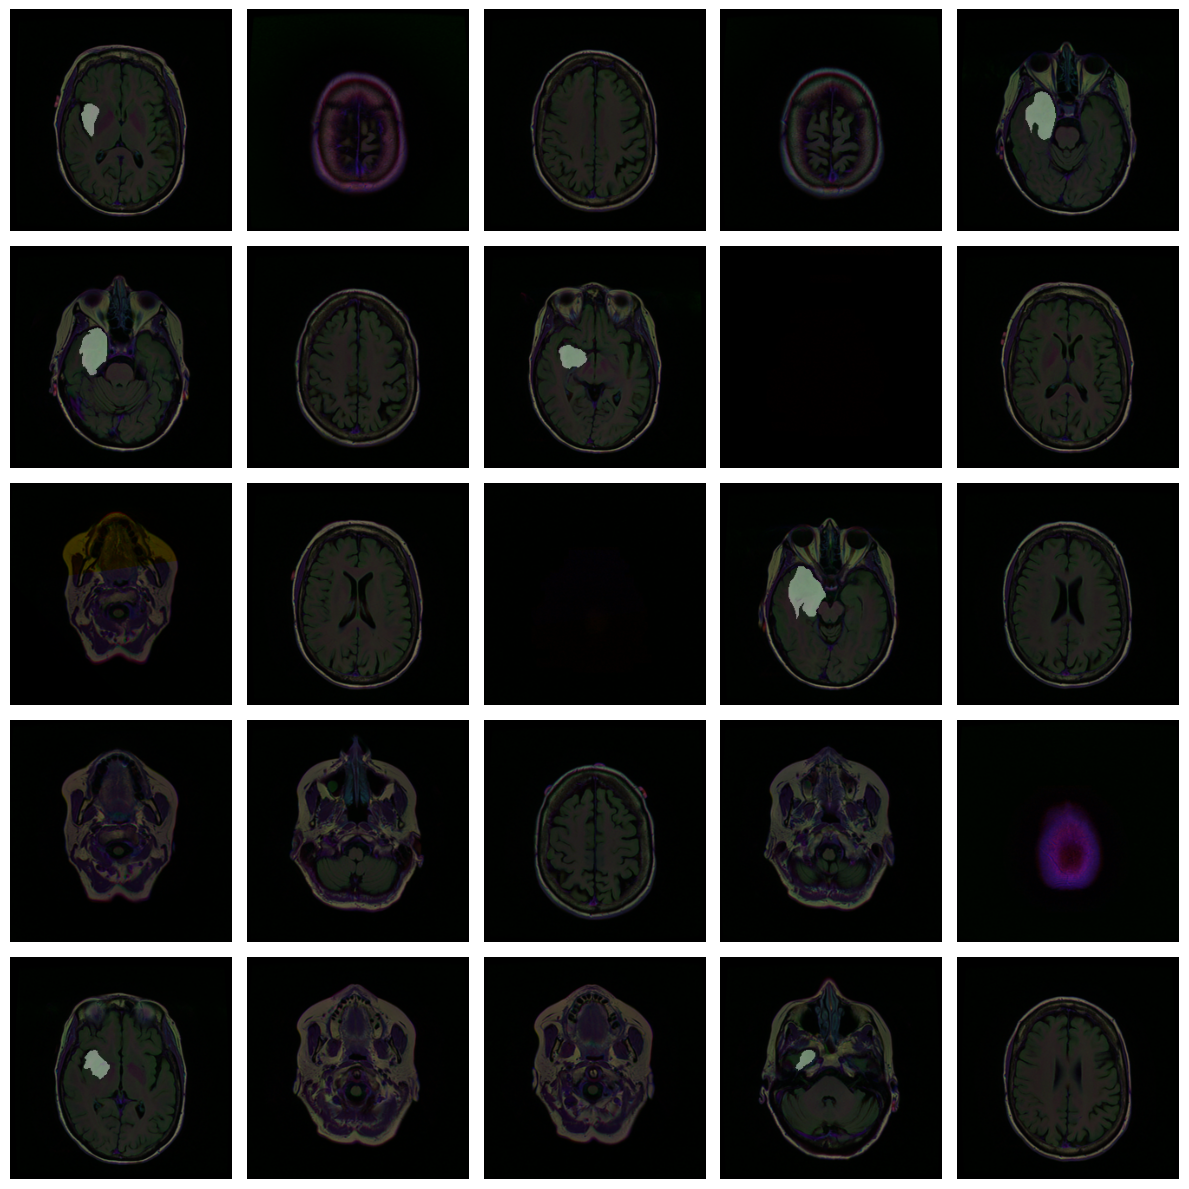

In [ ]:
# ================================================================
# TO DO: Prepare the full segmentation pipeline from scratch
#
# Follow these steps exactly:
# 1. Set the correct path to the dataset
# 2. Create DataFrame + perform patient-wise train/val/test split
#      → Use the function you implemented: create_df_and_split_patient_wise()
# 3. Define a rich augmentation dictionary for the training set only
#      Include: rotation, shift, shear, zoom, horizontal flip
# 4. Create DataLoaders using your create_loaders() function:
#      - Training loader: with augmentations, shuffle=True
#      - Validation & test loaders: no augmentations, shuffle=False is fine
#      - Use reasonable batch_size and num_workers (e.g. 4)
# 5. Visualize 25 random training samples with your show_images() function
# ================================================================

# TO DO: Define the root directory of the LGG MRI dataset
# Dataset link (for reference): https://www.kaggle.com/datasets/mateuszbuda/lgg-mri-segmentation
data_dir = '/kaggle/input/lgg-mri-segmentation/kaggle_3m'   # ← keep or adjust if needed

# TO DO: Create DataFrame and split patient-wise into train / val / test
train_df, valid_df, test_df = None

# TO DO: Define training augmentations (only applied to train set)
tr_aug_dict = {
    'rotation_range': None,        
    'width_shift_range': None,    
    'height_shift_range': None,   
    'shear_range': None,           
    'zoom_range': None,         
    'horizontal_flip': None,
}

# TO DO: Create DataLoaders
#     - Training: with augmentations + shuffling
#     - Validation & Test: no augmentations
#     Choose a suitable batch_size (32–64 works well on Kaggle/Colab)
batch_size = None
num_workers = None

train_loader = None 
valid_loader = None  
test_loader  = None  

# TO DO: Visualize a 5×5 grid of training images with segmentation masks overlaid
#     Use the function you implemented: show_images()
#     Pass lists of file paths (hint: .values or list(...) from DataFrame columns)

show_images(
    images = None,
    masks  = None
)

### Section 10: Model Initialization
Set device (GPU/CPU), instantiate U-Net, and choose optimizer (AdamW). Experiment with learning rates and print model summary to understand parameter count and architecture.

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet().to(device)

print(model)

UNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (act1): ReLU()
  (conv1_2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act1_2): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (act2): ReLU()
  (conv2_2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act2_2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (act3): ReLU()
  (conv3_2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_st

### Section 11: Training Loop
Implement the loop with progress bars, epoch timing, and checkpointing based on validation loss. During training, monitor for overfitting.

In [ ]:
# ================================================================
# TO DO: Configure the training hyperparameters and setup
#
# Complete the following:
# 1. Set the number of training epochs
# 2. Define batch size (keep consistent with your DataLoaders)
# 3. Instantiate the U-Net model and move it to GPU (if available)
# 4. Choose an optimizer:
#      → Use AdamW (better weight decay handling than Adam)
# 5. Define paths for saving the best model checkpoint
# 6. Initialize tracking variables
# ================================================================

# TO DO: Set number of epochs
epochs = None

# TO DO: Set batch size (must match what you used in DataLoaders)
batch_size = None

# TO DO: Define device (GPU if available, else CPU)
device = None
print(f"Using device: {device}")

# TO DO: Instantiate your UNet model and move to device
model = None       

# TO DO: Set optimizer (AdamW is recommended)
optimizer = None 

# TO DO: Define checkpoint path to save the best model
checkpoint_path = None   # .pth is standard for PyTorch models

# TO DO: Initialize best validation loss tracker
best_val_loss = None

# TO DO: Create a history dictionary to store training and validation metrics
history = {
    None
}

In [ ]:
# ================================================================
# TO DO: Implement a function to compute segmentation metrics
#
# Input:
#   y_true: ground truth masks
#   y_pred: model predictions
#
# Tasks:
# 1. Convert predictions to binary
# 2. Compute pixel-wise accuracy
# 3. Compute IoU using your implemented iou_coef() function
# 4. Compute Dice using your implemented dice_coef() function
# 5. Return all three metrics
# ================================================================

def compute_metrics(y_true, y_pred):
    
    # TO DO: Threshold predictions at 0.5 to get binary mask

    
    # TO DO: Compute pixel-wise accuracy

    
    # TO DO: Compute IoU using your iou_coef function

    
    # TO DO: Compute Dice coefficient using your dice_coef function

    
    return acc, iou, dice

In [ ]:
# ================================================================
# TO DO: Implement the training loop for ONE epoch
#
# Tasks:
# 1. Set model to training mode
# 2. Initialize running totals for loss, accuracy, IoU, and Dice
# 3. Loop over the DataLoader
# 4. For each batch:
#      • Move images and masks to the correct device (GPU/CPU)
#      • Zero the gradients
#      • Forward pass: get predictions
#      • Compute loss
#      • Backward pass + optimizer step
#      • Compute metrics
#      • Accumulate loss and metrics
# 5. After all batches: return AVERAGE loss, acc, iou, dice over the epoch
# ================================================================

def train_epoch(loader, model, optimizer, device):
    
    # TO DO: Set model to training mode

    
    # TO DO: Initialize accumulators

    
    for img, msk in loader:
        
        # TO DO: Move data to device
        img = None
        msk = None
        
        # TO DO: Zero gradients

        
        # TO DO: Forward pass

        
        # TO DO: Compute combined loss

        
        # TO DO: Backward pass and optimization step

        
        # TO DO: Compute metrics (use your function)

        
        # TO DO: Accumulate values (use .item()!)

    
    # TO DO: Return average metrics over the epoch
    return None


# ================================================================
# TO DO: Implement the validation loop for ONE epoch
#
# Same as training, but:
#   • Set model to eval mode
#   • Wrap everything in torch.no_grad()
#   • NO optimizer.zero_grad(), NO backward(), NO optimizer.step()
#   • Still compute loss and metrics for monitoring
# ================================================================

def val_epoch(loader, model, device):
    
    # TO DO: Set model to evaluation mode

    
    # TO DO: Initialize accumulators

    
    # Disable gradient computation
    with torch.no_grad():
        for img, msk in loader:
            
            # TO DO: Move data to device
            img = None
            msk = None
            
            # TO DO: Forward pass only

            
            # TO DO: Compute loss (for monitoring) and metrics

            
            # TO DO: Accumulate

    
    # TO DO: Return average validation metrics
    return None

In [ ]:
print(f"Training on: {device}")
print(f"Total epochs: {epochs} | Batch size: {batch_size}")
print(f"Train batches: {len(train_loader)} | Valid batches: {len(valid_loader)}")
print("-" * 80)

# TO DO: Re-initialize the best validation loss tracker
 

# TO DO: Define the path where the best model checkpoint will be saved


# TO DO: Loop over all epochs (from 1 to epochs inclusive)
for epoch in range(1, epochs + 1):
    start_time = time.time()

    # ==================== TRAINING PHASE ====================
    # TO DO: Set model to training mode

    # TO DO: Create empty lists to collect per-batch training metrics
    #     (loss, accuracy, iou, dice)

    print(f"\nEpoch {epoch}/{epochs} [TRAINING]")
    # TO DO: Iterate over train_loader with tqdm progress bar

        # TO DO: Move images and masks to the correct device 
        
        # TO DO: Zero the optimizer gradients

        # TO DO: Forward pass

        # TO DO: Compute the combined loss

        # TO DO: Backward pass and optimizer step

        # TO DO: Threshold predictions (get binary masks)

        # TO DO: Compute accuracy, IoU, and Dice for this batch

        # TO DO: Append all batch metrics to their respective lists


    # TO DO: Compute epoch-level averages for all training metrics


    # ==================== VALIDATION PHASE ====================
    # TO DO: Set model to evaluation mode

    # TO DO: Create empty lists for validation metrics

    print(f"Epoch {epoch}/{epochs} [VALIDATING]")
    # TO DO: Disable gradient computation for validation

        # TO DO: Iterate over valid_loader with tqdm

            # TO DO: Move data to device

            # TO DO: Forward pass only

            # TO DO: Compute loss

            # TO DO: Threshold predictions

            # TO DO: Compute accuracy, IoU, and Dice

            # TO DO: Append batch metrics to validation lists


    # TO DO: Compute epoch-level averages for all validation metrics


    # ==================== LOGGING ====================
    # TO DO: Calculate time taken for this epoch and estimated time remaining

    # TO DO: Print a clean summary with train and validation metrics
    #     Include: loss, accuracy, IoU, Dice (formatted nicely)

    # TO DO: Append all epoch metrics to the history dictionary


    # ==================== CHECKPOINTING ====================
    # TO DO: If current validation loss is better than the best so far:
    #     • Update best_val_loss
    #     • Save model state_dict, optimizer state_dict, epoch, and metrics
    #     • Print confirmation message
    # Otherwise: print that no improvement was made


    print("=" * 70)


# TO DO: After all epochs, print final success message with best validation loss and checkpoint path

Training on: cuda
Total epochs: 50 | Batch size: 40
Train batches: 80 | Valid batches: 9
--------------------------------------------------------------------------------

Epoch 1/50 [TRAINING]


Epoch 1/50 [VALIDATING]



==================== EPOCH 1/50 SUMMARY ====================
Time: 86.1s | ETA: 70.4 min
TRAIN  → Loss: 1.16432 | Acc: 0.9747 | IoU: 0.2805 | Dice: 0.4231
VALID  → Loss: 0.99669 | Acc: 0.9889 | IoU: 0.4275 | Dice: 0.5958
Best model saved! (Val Loss: 0.99669)

Epoch 2/50 [TRAINING]


Epoch 2/50 [VALIDATING]



==================== EPOCH 2/50 SUMMARY ====================
Time: 83.8s | ETA: 67.1 min
TRAIN  → Loss: 0.82122 | Acc: 0.9873 | IoU: 0.3311 | Dice: 0.4871
VALID  → Loss: 0.61511 | Acc: 0.9917 | IoU: 0.4200 | Dice: 0.5874
Best model saved! (Val Loss: 0.61511)

Epoch 3/50 [TRAINING]


...


==================== EPOCH 48/50 SUMMARY ====================
Time: 83.9s | ETA: 2.8 min
TRAIN  → Loss: 0.16550 | Acc: 0.9971 | IoU: 0.7455 | Dice: 0.8529
VALID  → Loss: 0.23516 | Acc: 0.9945 | IoU: 0.6696 | Dice: 0.7997
No improvement (best: 0.23465)

Epoch 49/50 [TRAINING]


Epoch 49/50 [VALIDATING]



==================== EPOCH 49/50 SUMMARY ====================
Time: 83.9s | ETA: 1.4 min
TRAIN  → Loss: 0.15856 | Acc: 0.9972 | IoU: 0.7549 | Dice: 0.8593
VALID  → Loss: 0.20815 | Acc: 0.9957 | IoU: 0.7006 | Dice: 0.8228
Best model saved! (Val Loss: 0.20815)

Epoch 50/50 [TRAINING]


Epoch 50/50 [VALIDATING]



==================== EPOCH 50/50 SUMMARY ====================
Time: 83.8s | ETA: 0.0 min
TRAIN  → Loss: 0.15416 | Acc: 0.9973 | IoU: 0.7612 | Dice: 0.8630
VALID  → Loss: 0.28190 | Acc: 0.9942 | IoU: 0.6205 | Dice: 0.7633
No improvement (best: 0.20815)

Training completed! Best validation loss: 0.20815
Best model saved at: unet_best.pth


### Section 12: Loading the Best Model
Load the checkpointed model state. Verify loading (e.g., print epoch/val_loss) and optionally resume training from here for more epochs.

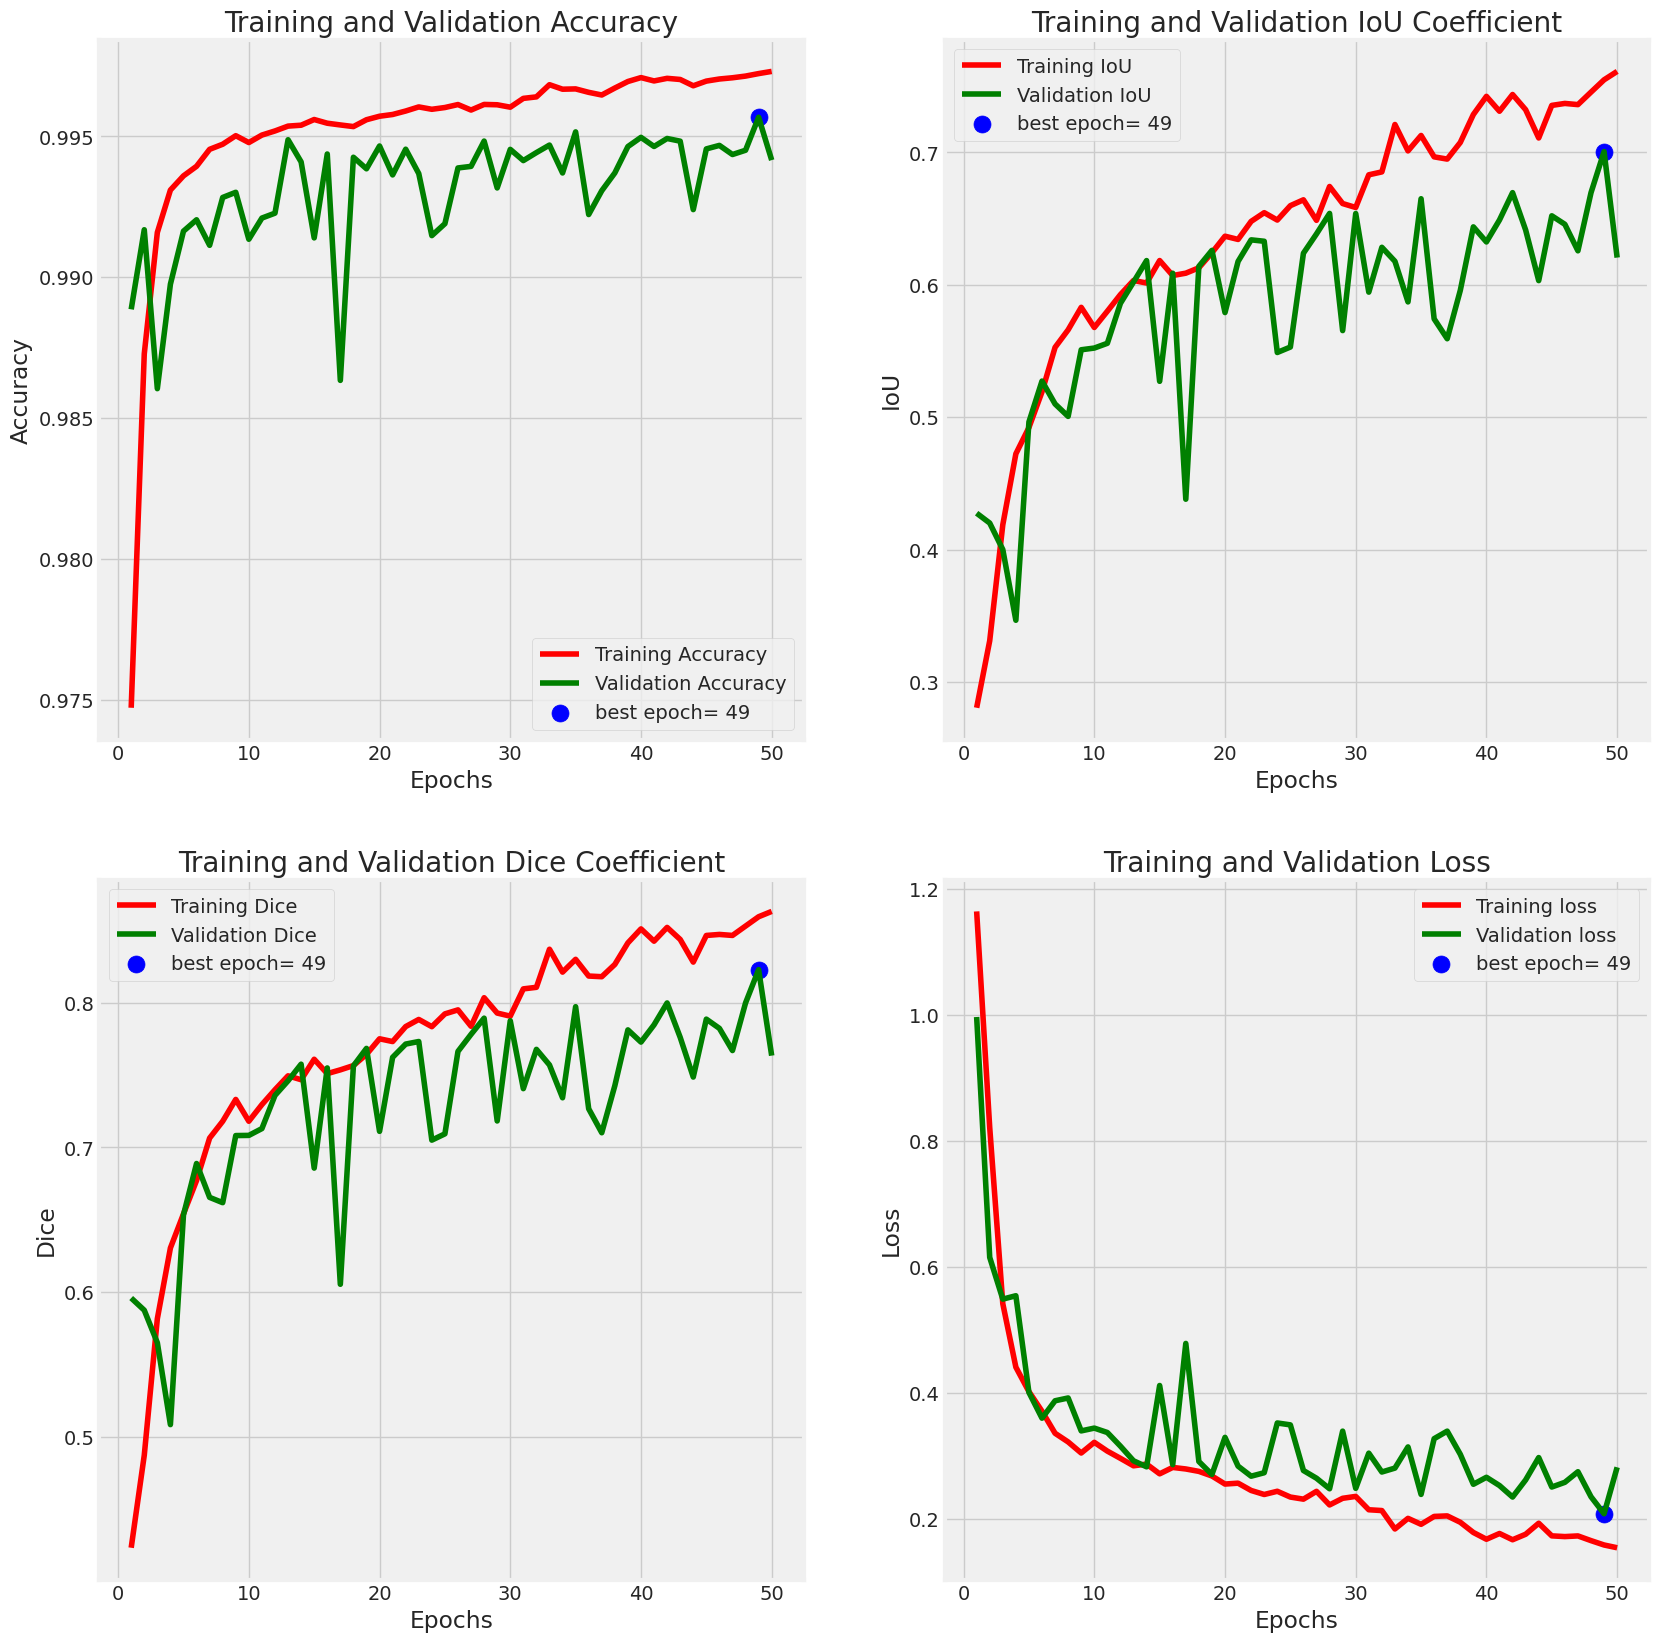

Loaded model from epoch 49 with val_loss 0.20815


In [ ]:
# ================================================================
# TO DO: Load the best trained model and visualize results
# ================================================================

# TO DO: Load the saved checkpoint from disk using torch.load()


# TO DO: Load the model state dictionary from the checkpoint into your model
#     This restores the best-performing weights

# TO DO: Call the plot_training() function to display the training curves
#     (loss, Dice coefficient, IoU over epochs)

print(f"Loaded model from epoch {checkpoint.get('epoch', '?')} with val_loss {checkpoint.get('val_loss', '?'):.5f}")

### Section 13: Model Evaluation
Define evaluation on train/valid/test loaders and print scores.

In [ ]:
# ================================================================
# TO DO: Final Evaluation on Train / Validation / Test sets
#
# Tasks:
# 1. Define a helper function (or directly compute) that runs a full pass 
#     over a given DataLoader using your val_epoch() function 
#     and returns average loss, accuracy, IoU, and Dice
# 2. Evaluate the best loaded model on:
#     • Training set
#     • Validation set  
#     • Test set
# 3. Print all metrics clearly separated for each split
#     Format: Loss, Accuracy, IoU, Dice
#     Use clean separation lines between splits
# ================================================================

# TO DO: Write a function (e.g. evaluate()) that reuses val_epoch()
#     to compute and return the four metrics for any loader


# TO DO: Evaluate the best model on training set


# TO DO: Evaluate the best model on validation set


# TO DO: Evaluate the best model on test set


# TO DO: Print final performance summary
#     Include all four metrics for Train / Valid / Test splits
#     Use clear formatting and separators

Train Loss:  0.1455503709614277
Train Accuracy:  0.9975265435874462
Train IoU:  0.7717886060476303
Train Dice:  0.8702478252351284
--------------------
Valid Loss:  0.21897836691803402
Valid Accuracy:  0.9955398705270555
Valid IoU:  0.6860323746999105
Valid Dice:  0.8125380542543199
--------------------
Test Loss:  0.2672531252557581
Test Accuracy:  0.9964268207550049
Test IoU:  0.6816491809758273
Test Dice:  0.806541545824571


*Question*: Based on your results, explain why accuracy is not a suitable metric for this task?

*Answer*: 

### Section 15: Predictions and Visualization
Generate predictions on test samples and visualize original image/mask vs. prediction. Qualitatively assess segmentation quality (e.g., on small tumors), and look for false positives/negatives.

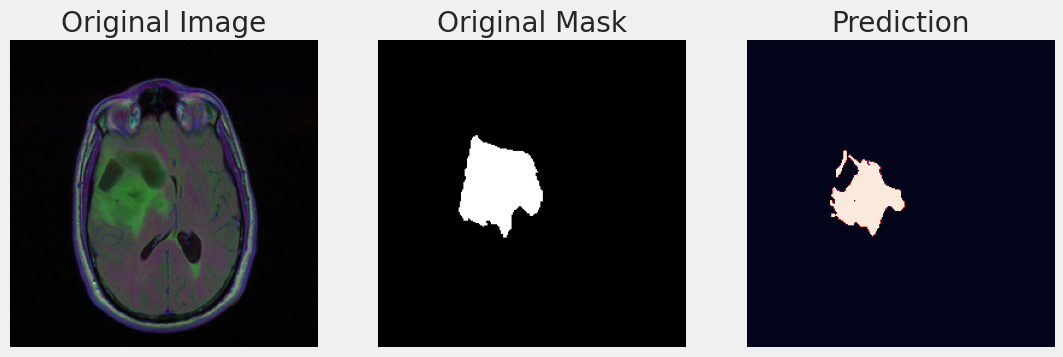

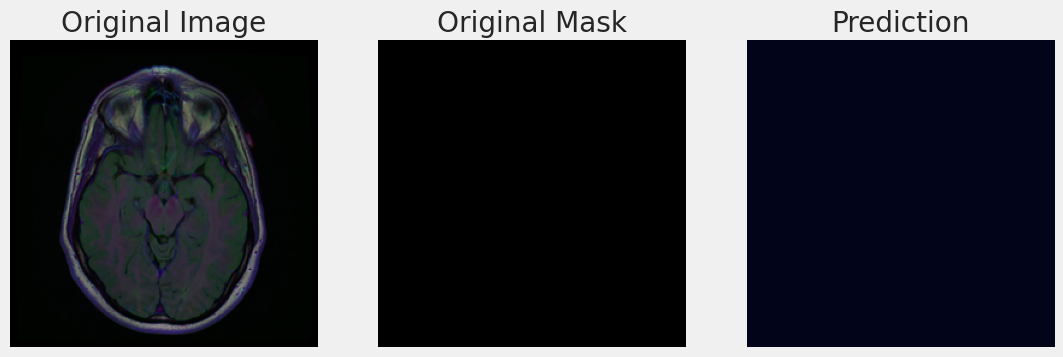

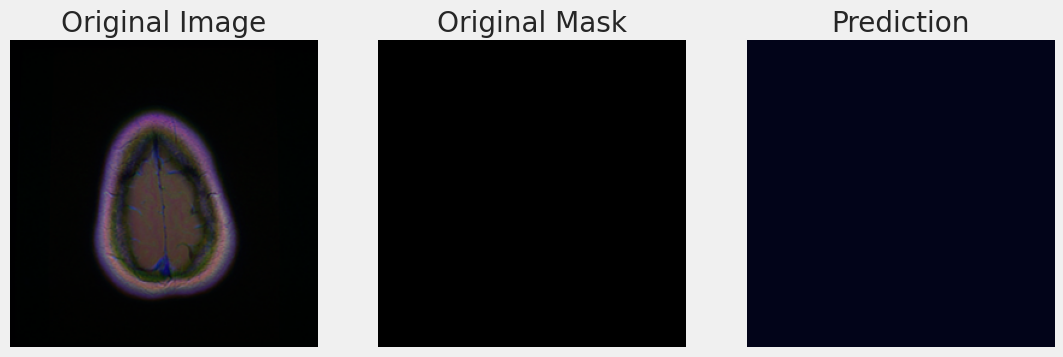

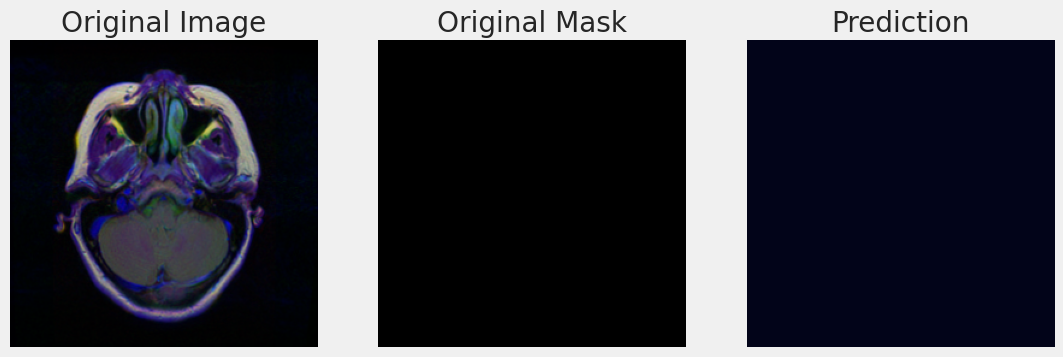

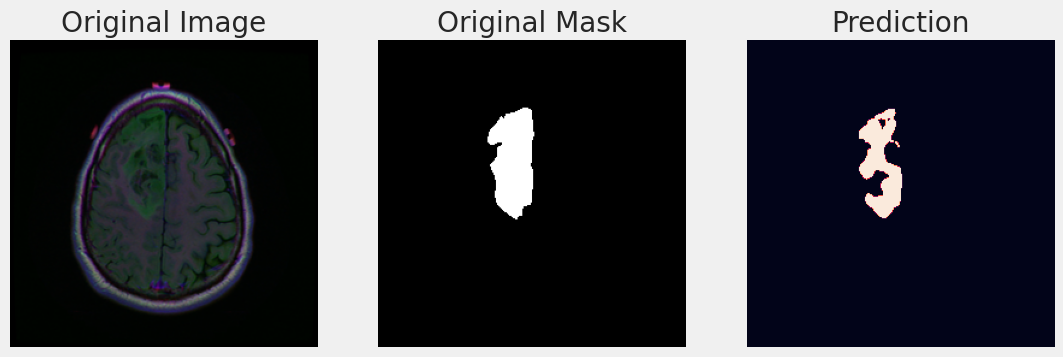

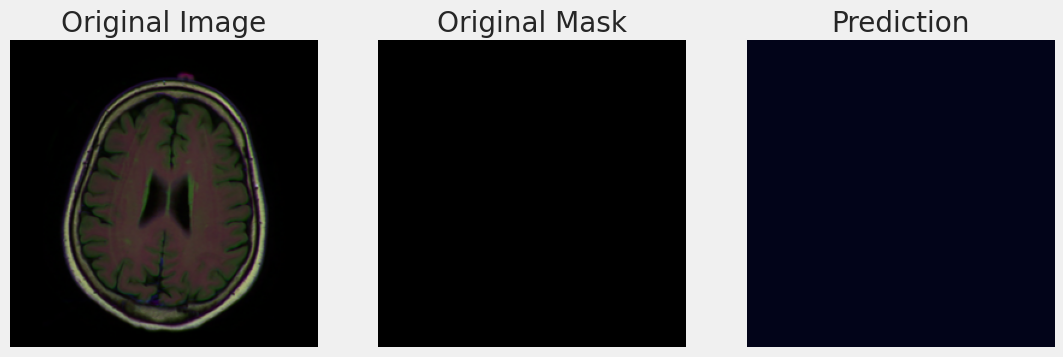

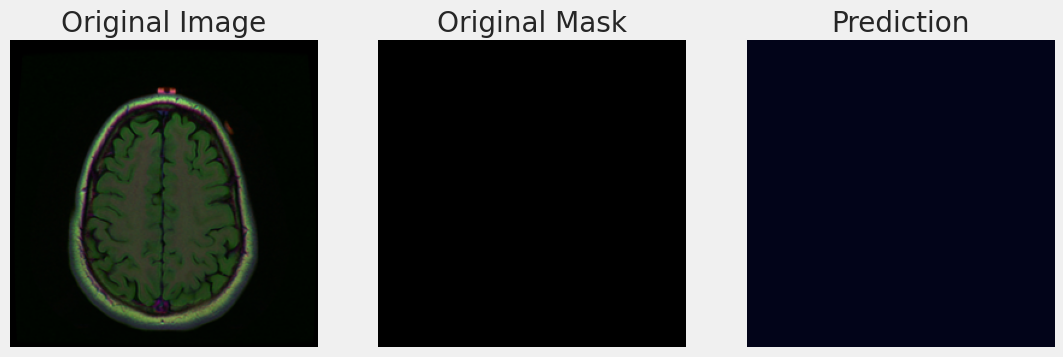

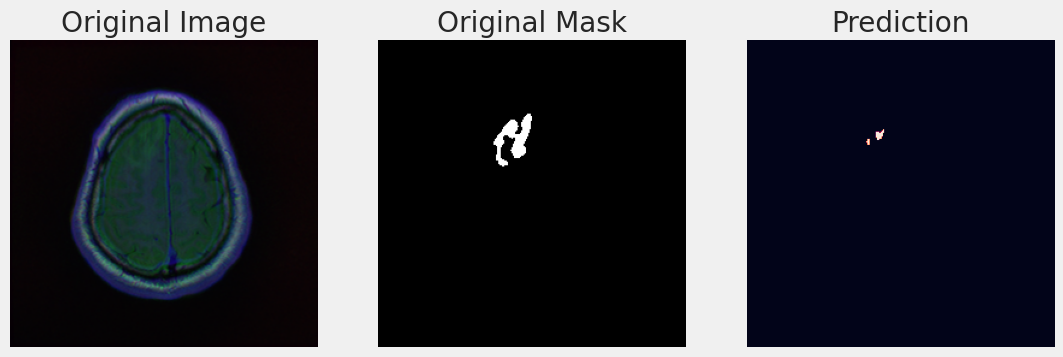

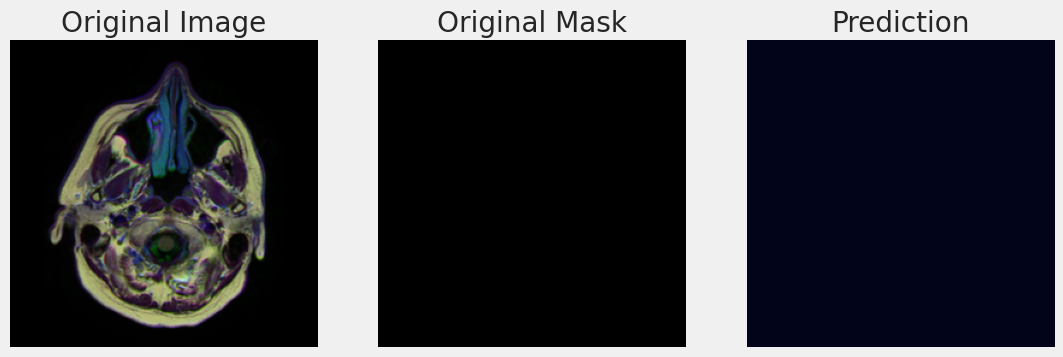

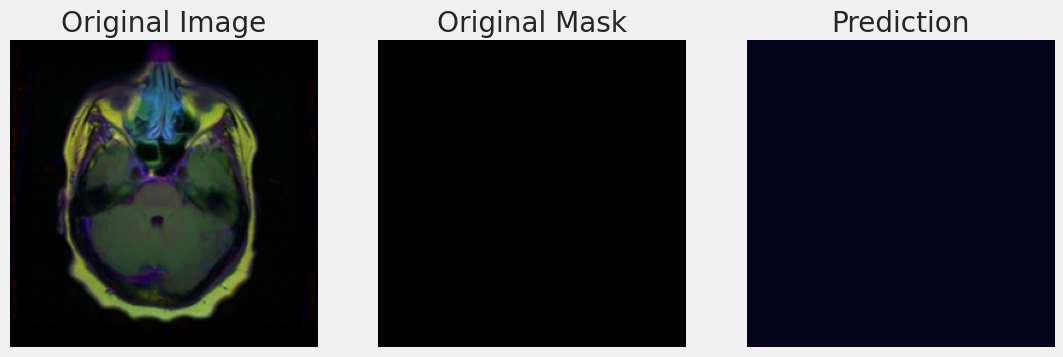

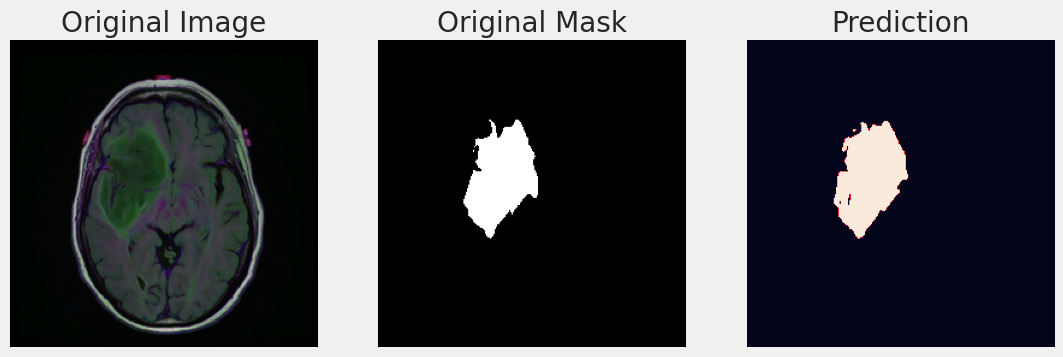

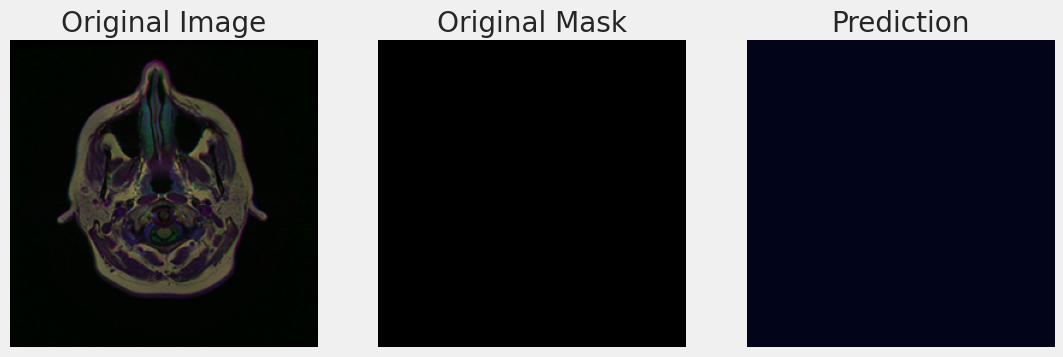

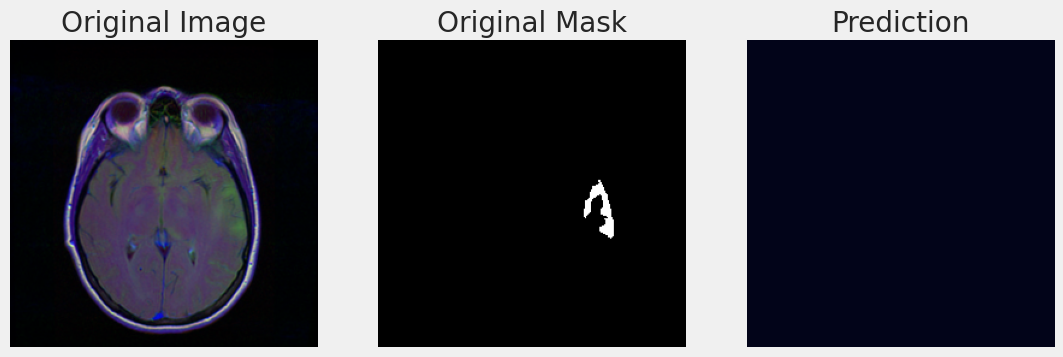

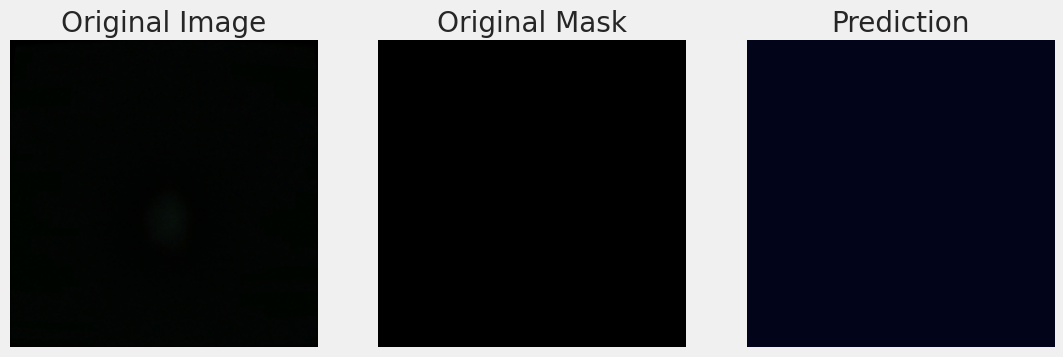

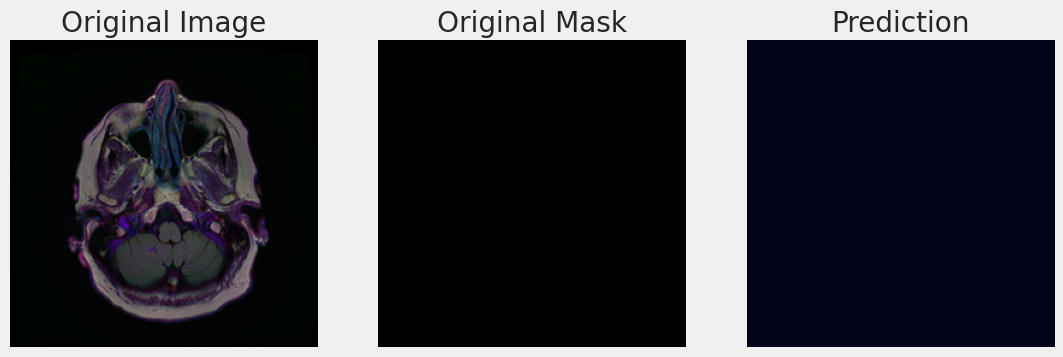

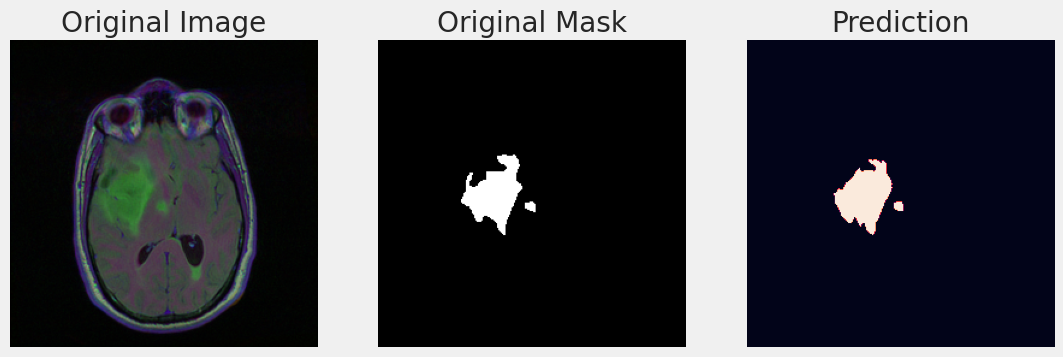

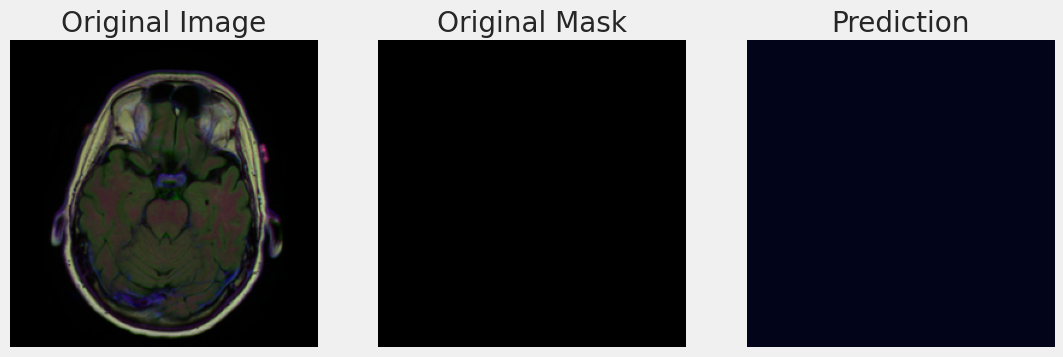

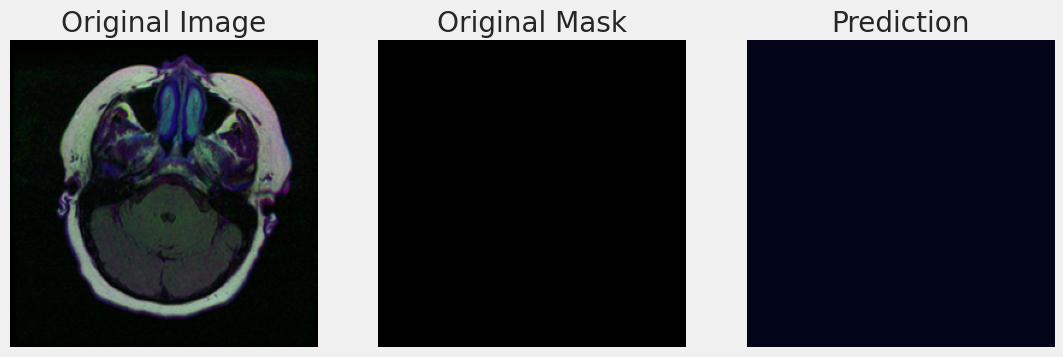

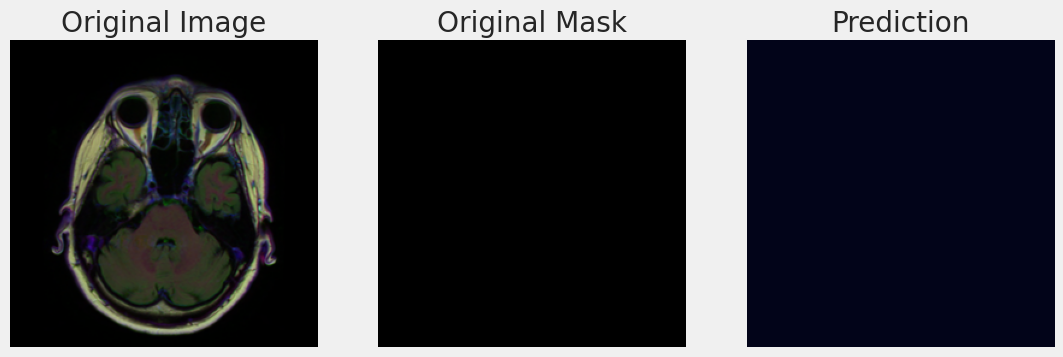

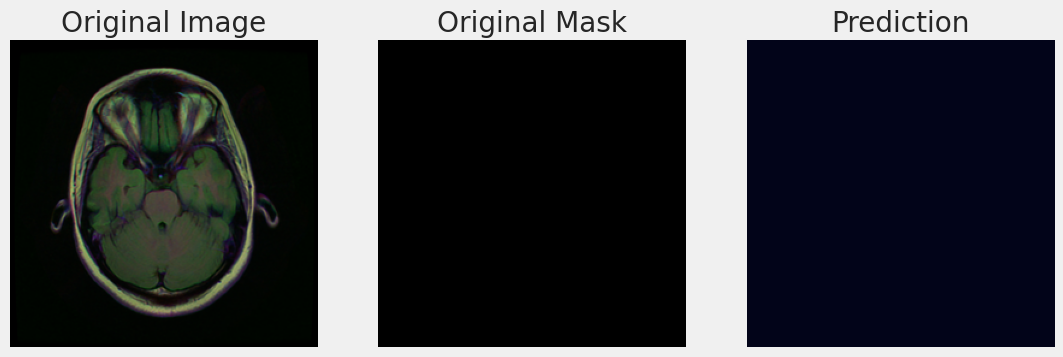

In [16]:
model.eval()
for _ in range(20):
    index = np.random.randint(1, len(test_df.index))
    img = cv2.imread(test_df['images_paths'].iloc[index])
    img = cv2.resize(img, (256, 256))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_tensor = transforms.ToTensor()(img).unsqueeze(0).to(device)  # No /255 since ToTensor does it

    with torch.no_grad():
        predicted_img = model(img_tensor)

    plt.figure(figsize=(12, 12))
    
    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.axis('off')
    plt.title('Original Image')

    plt.subplot(1, 3, 2)
    plt.imshow(np.squeeze(cv2.imread(test_df['masks_paths'].iloc[index])))
    plt.axis('off')
    plt.title('Original Mask')

    plt.subplot(1, 3, 3)
    plt.imshow(np.squeeze(predicted_img.cpu().numpy()) > 0.5 )
    plt.title('Prediction')
    plt.axis('off')
    
    plt.show()